# 4. Results — and the check against the frozen numbers

Everything here is arithmetic on the two tables from notebook 3. Each cell answers one question, in plain words first.

In [1]:
import sys; sys.path.insert(0, "..")
import json, time, os
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import helpers as h
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

In [2]:
original = pd.read_csv("../results/stars_original.csv")
replication = pd.read_csv("../results/stars_replication.csv")
frozen = json.load(open("../data/frozen_numbers.json"))
bins = np.arange(3000, 6001, 200)
def bin_of(teff): return (np.clip(np.digitize(teff, bins) - 1, 0, len(bins) - 2)) * 200 + 3000
for t in (original, replication): t["bin"] = bin_of(t.teff.to_numpy())
print(len(original), "original stars,", len(replication), "replication stars")

450 original stars, 422 replication stars


## Q1. How does the wander change with temperature?

For each 200 K slice: the median wander, the median floors, and the median excess (in quadrature) under each floor.

In [3]:
def bin_table(t):
    g = t.groupby("bin")
    return pd.DataFrame({
        "n": g.size(),
        "wander": g.wander.median(),
        "floor_white": g.floor_white.median(),
        "floor_shifted": g.floor_shifted.median(),
        "excess_white": g.excess_white.median(),
        "excess_shifted": g.excess_shifted.median(),
        "share_above_0.015_shifted": g.excess_shifted.apply(lambda x: (x > h.FIXED_THRESHOLD).mean()),
    })
bt = bin_table(original); bt_rep = bin_table(replication)
print("Original sample, per 200 K slice (rad/day):"); bt.round(4)

Original sample, per 200 K slice (rad/day):


,n,wander,floor_white,floor_shifted,excess_white,excess_shifted,share_above_0.015_shifted
bin,,,,,,,
3000,30,0.0141,0.0055,0.0096,0.0125,0.0104,0.2667
3200,30,0.0106,0.0039,0.0082,0.0081,0.0041,0.1000
3400,30,0.0114,0.0031,0.0081,0.0101,0.0069,0.2000
3600,30,0.0121,0.0032,0.0068,0.0117,0.0088,0.4000
3800,30,0.0099,0.0030,0.0066,0.0091,0.0074,0.2667
4000,30,0.0129,0.0032,0.0075,0.0126,0.0086,0.3667
4200,30,0.0116,0.0017,0.0062,0.0116,0.0106,0.3000
4400,30,0.0157,0.0022,0.0078,0.0155,0.0144,0.5000
4600,30,0.0177,0.0017,0.0073,0.0174,0.0149,0.5000


adopted floor: hot slices (>=5000 K) excess 0.019-0.050; cool slices (<3800 K) 0.004-0.010 rad/day  -> ratio of medians 3.8x


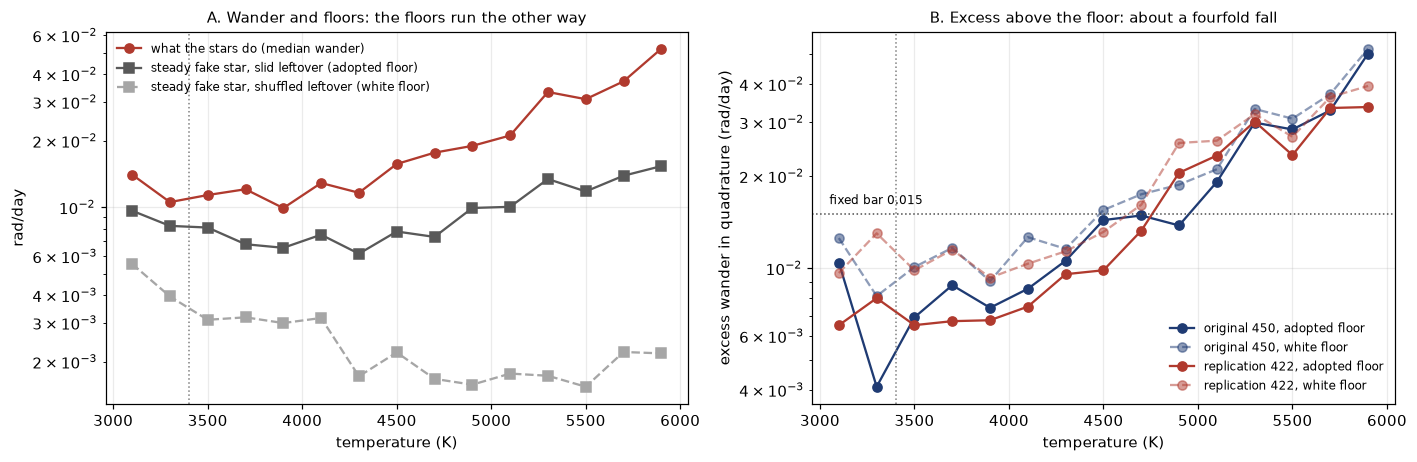

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.plot(bt.index + 100, bt.wander, "o-", color="#b03a2e", label="what the stars do (median wander)")
ax.plot(bt.index + 100, bt.floor_shifted, "s-", color="0.35", label="steady fake star, slid leftover (adopted floor)")
ax.plot(bt.index + 100, bt.floor_white, "s--", color="0.65", label="steady fake star, shuffled leftover (white floor)")
ax.set_yscale("log"); ax.set_ylabel("rad/day"); ax.set_title("A. Wander and floors: the floors run the other way", fontsize=10)
ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.25)
ax = axes[1]
for t_, col, lab in [(bt, "#1f3b73", "original 450"), (bt_rep, "#b03a2e", "replication 422")]:
    ax.plot(t_.index + 100, t_.excess_shifted, "o-", color=col, label=f"{lab}, adopted floor")
    ax.plot(t_.index + 100, t_.excess_white, "o--", color=col, alpha=0.5, label=f"{lab}, white floor")
ax.axhline(h.FIXED_THRESHOLD, color="0.3", ls=":", lw=1); ax.text(3050, h.FIXED_THRESHOLD * 1.08, "fixed bar 0.015", fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("excess wander in quadrature (rad/day)"); ax.set_title("B. Excess above the floor: about a fourfold fall", fontsize=10)
ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.25)
for ax in axes: ax.set_xlabel("temperature (K)"); ax.axvline(3400, color="0.5", ls=":", lw=1)
fig.tight_layout(); fig.savefig("../figures/04_trend.png", dpi=150)
hot = bt.loc[bt.index >= 5000, "excess_shifted"]; cool = bt.loc[bt.index < 3800, "excess_shifted"]
print(f"adopted floor: hot slices (>=5000 K) excess {hot.min():.3f}-{hot.max():.3f}; cool slices (<3800 K) {cool.min():.3f}-{cool.max():.3f} rad/day  -> ratio of medians {hot.median()/cool.median():.1f}x")

## Q2. A fixed bar that does not depend on the floor

Draw one line at 0.015 rad/day of excess wander and count how many stars clear it, Sun-like (≥ 5,000 K) versus mid-M (< 3,400 K). The line is about twice the median adopted floor of the coolest slices (0.008–0.010 rad/day) and far below the Sun-like wander (0.03–0.05), so it is the same bar for every star. The cell after the table moves the bar to show that its exact position does not matter.

In [5]:
def shares(t, floor):
    cool = t[t.teff < 3400]; hot = t[t.teff >= 5000]
    return (cool[f"excess_{floor}"] > h.FIXED_THRESHOLD).mean(), (hot[f"excess_{floor}"] > h.FIXED_THRESHOLD).mean(), len(cool), len(hot)
rows = []
for sname, t in [("original", original), ("replication", replication)]:
    for floor in ("shifted", "white"):
        c, hh, nc, nh = shares(t, floor)
        rows.append(dict(sample=sname, floor=floor, cool_lt_3400=f"{100*c:.0f}% of {nc}", hot_ge_5000=f"{100*hh:.0f}% of {nh}"))
fixed_bar = pd.DataFrame(rows); fixed_bar

,sample,floor,cool_lt_3400,hot_ge_5000
0,original,shifted,18% of 60,83% of 150
1,original,white,22% of 60,88% of 150
2,replication,shifted,15% of 52,78% of 130
3,replication,white,25% of 52,88% of 130


In [6]:
# Does the choice of 0.015 matter? Move the bar and watch the two shares.
rows = []
for thr in (0.010, 0.012, 0.015, 0.020, 0.025, 0.030):
    for sname, t in [("original", original), ("replication", replication)]:
        cool = t[t.teff < 3400]; hot = t[t.teff >= 5000]
        c, hh = (cool.excess_shifted > thr).mean(), (hot.excess_shifted > thr).mean()
        rows.append(dict(threshold=thr, sample=sname, sunlike_share=round(100 * hh), midM_share=round(100 * c), ratio=round(hh / c, 1) if c > 0 else np.inf))
sweep = pd.DataFrame(rows).pivot(index="threshold", columns="sample", values=["sunlike_share", "midM_share", "ratio"])
print("adopted floor; shares in %, ratio = Sun-like share / mid-M share")
sweep

adopted floor; shares in %, ratio = Sun-like share / mid-M share


sunlike_share             midM_share                ratio            
sample         original replication   original replication original replication
threshold                                                                      
0.010              91.0        88.0       40.0        40.0      2.3         2.2
0.012              89.0        83.0       28.0        27.0      3.1         3.1
0.015              83.0        78.0       18.0        15.0      4.5         5.1
0.020              69.0        62.0       15.0         8.0      4.6         8.0
0.025              59.0        55.0       15.0         4.0      4.0        14.2
0.030              50.0        42.0        8.0         4.0      6.0        11.0

## Q3. The trend as one number, holding the nuisance variables fixed

A straight line through log₁₀(excess ratio) against temperature, with period, amplitude, brightness and sector count in the same fit so they cannot masquerade as temperature. The error bars are "robust" (they do not assume every star is equally noisy). We also add a "step below 3,400 K" term to see whether the boundary needs one.

In [7]:
from scipy import stats
def trend(t, floor):
    keep = t[np.isfinite(t[f"ratio_{floor}"]) & (t[f"ratio_{floor}"] > 0)]
    y = np.log10(keep[f"ratio_{floor}"].to_numpy())
    X, names = h.design_matrix(keep); coef, se = h.robust_fit(X, y)
    Xs, names_s = h.design_matrix(keep, with_step=True); coef_s, se_s = h.robust_fit(Xs, y)
    rho = stats.spearmanr(keep.teff, keep[f"ratio_{floor}"]).statistic
    i = names.index("teff_per_1000K"); j = names_s.index("step_below_3400K")
    return dict(n=len(keep), spearman_rho=rho, coef=coef[i], se=se[i], t=coef[i] / se[i], step=coef_s[j], step_se=se_s[j], step_t=coef_s[j] / se_s[j])
rows = []
for sname, t in [("original", original), ("replication", replication)]:
    for floor in ("shifted", "white"):
        r = trend(t, floor); r.update(sample=sname, floor=floor); rows.append(r)
trend_table = pd.DataFrame(rows)[["sample", "floor", "n", "spearman_rho", "coef", "se", "t", "step", "step_se", "step_t"]]
print("coef = dex of excess ratio per 1,000 K (0.13 dex = x1.35 per 1,000 K); step = extra jump below 3,400 K, in dex")
trend_table.round(3)

coef = dex of excess ratio per 1,000 K (0.13 dex = x1.35 per 1,000 K); step = extra jump below 3,400 K, in dex


,sample,floor,n,spearman_rho,coef,se,t,step,step_se,step_t
0,original,shifted,450,0.438,0.127,0.021,6.120,-0.005,0.042,-0.109
1,original,white,450,0.675,0.279,0.029,9.705,0.043,0.058,0.742
2,replication,shifted,422,0.432,0.109,0.023,4.771,0.037,0.037,1.007
3,replication,white,422,0.673,0.244,0.030,8.092,0.062,0.053,1.159


## Q4. Does the wander depend on how fast the star spins?

Slope of log₁₀(excess in quadrature) per doubling of the rotation period, holding amplitude, brightness and sector count fixed, in three temperature groups.

In [8]:
groups = {"cool 3000-3800 K": (3000, 3800), "mid 3800-4800 K": (3800, 4800), "hot 4800-6000 K": (4800, 6000)}
rows = []
for sname, t in [("original", original), ("replication", replication)]:
    for floor in ("shifted", "white"):
        for gname, (lo, hi) in groups.items():
            r = h.period_slope(t[(t.teff >= lo) & (t.teff < hi)], floor); r.update(sample=sname, floor=floor, group=gname); rows.append(r)
period_table = pd.DataFrame(rows)[["sample", "floor", "group", "n", "estimate", "hc_se", "t"]]
period_table.round(3)

,sample,floor,group,n,estimate,hc_se,t
0,original,shifted,cool 3000-3800 K,92,0.187,0.058,3.216
1,original,shifted,mid 3800-4800 K,136,0.134,0.043,3.131
2,original,shifted,hot 4800-6000 K,171,-0.032,0.048,-0.672
3,original,white,cool 3000-3800 K,112,0.182,0.044,4.095
4,original,white,mid 3800-4800 K,145,0.151,0.031,4.836
5,original,white,hot 4800-6000 K,180,0.042,0.043,0.980
6,replication,shifted,cool 3000-3800 K,86,0.102,0.053,1.950
7,replication,shifted,mid 3800-4800 K,127,0.095,0.041,2.338
8,replication,shifted,hot 4800-6000 K,149,0.024,0.058,0.419
9,replication,white,cool 3000-3800 K,104,0.177,0.046,3.879


## Q5. Early versus late mission

The cadence changed from 30 minutes (sectors ≤ 60) to 10 minutes / 200 s (sectors ≥ 61). If the wander were an instrument effect, the early/late ratio should depend on temperature. Does it?

In [9]:
both = original[np.isfinite(original.early_wander) & np.isfinite(original.late_wander) & (original.late_wander > 0)]
ratio = np.log10(both.early_wander / both.late_wander)
r = stats.spearmanr(both.teff, ratio)
print(f"{len(both)} stars observed in both eras; median log10(early/late) = {ratio.median():+.3f}; Spearman(temperature, early/late) rho = {r.statistic:+.3f}, p = {r.pvalue:.2f}")

390 stars observed in both eras; median log10(early/late) = +0.047; Spearman(temperature, early/late) rho = +0.040, p = 0.44


## Q6. The replication against the rules written beforehand

From `REPLICATION_PLAN.md` (written 1 Sep 2026 before the 422 stars were drawn), for the white floor then in use:

1. **Trend:** coefficient between +0.20 and +0.35 dex per 1,000 K, Spearman ρ > 0.5.
2. **G/K period independence:** slope per doubling in 4,800–6,000 K within ±0.10 dex.
3. **M-dwarf period dependence:** slope per doubling in 3,000–3,800 K > +0.10 dex.

In [10]:
rw = trend_table[(trend_table["sample"] == "replication") & (trend_table.floor == "white")].iloc[0]
pw = period_table[(period_table["sample"] == "replication") & (period_table.floor == "white")].set_index("group")
checks = pd.DataFrame([
    dict(prediction="1. trend +0.20..+0.35, rho>0.5", value=f"{rw.coef:+.3f} ± {rw.se:.3f}, rho={rw.spearman_rho:.2f}", met=bool(0.20 <= rw.coef <= 0.35 and rw.spearman_rho > 0.5)),
    dict(prediction="2. hot slope within ±0.10", value=f"{pw.loc['hot 4800-6000 K','estimate']:+.3f} ± {pw.loc['hot 4800-6000 K','hc_se']:.3f}", met=bool(abs(pw.loc["hot 4800-6000 K", "estimate"]) <= 0.10)),
    dict(prediction="3. cool slope > +0.10", value=f"{pw.loc['cool 3000-3800 K','estimate']:+.3f} ± {pw.loc['cool 3000-3800 K','hc_se']:.3f}", met=bool(pw.loc["cool 3000-3800 K", "estimate"] > 0.10)),
]); checks

,prediction,value,met
0,"1. trend +0.20..+0.35, rho>0.5","+0.244 ± 0.030, rho=0.67",True
1,2. hot slope within ±0.10,+0.077 ± 0.051,True
2,3. cool slope > +0.10,+0.177 ± 0.046,True


## Q7. Do these notebooks reproduce the frozen numbers?

The abstract was frozen from the full pipeline on 1–2 September. The same quantities from these notebooks are put side by side. Tolerances: 0.005 dex on coefficients and slopes, 0.5% on shares, 0.3 on t-values, 2% on bin medians.

In [11]:
def frozen_run(sname, floor): return frozen[f"{sname}_{floor}"]
rows = []
for sname, t in [("original", original), ("replication", replication)]:
    for floor in ("shifted", "white"):
        fz = frozen_run(sname, floor); tr = trend_table[(trend_table["sample"] == sname) & (trend_table.floor == floor)].iloc[0]
        c, hh, _, _ = shares(t, floor)
        pt = period_table[(period_table["sample"] == sname) & (period_table.floor == floor)].set_index("group")
        bt_ = bin_table(t)
        items = [
            ("temperature coefficient (dex/1000 K)", tr.coef, fz["teff_coefficient_dex_per_1000K"]["estimate"], 0.005),
            ("  its robust standard error", tr.se, fz["teff_coefficient_dex_per_1000K"]["hc_se"], 0.003),
            ("  t-value", tr.t, fz["teff_coefficient_dex_per_1000K"]["t"], 0.3),
            ("Spearman rho(temperature, excess ratio)", tr.spearman_rho, fz["spearman_teff_vs_excess_ratio"], 0.01),
            ("step below 3400 K, t-value", tr.step_t, fz["step_indicator_3400K"]["t"], 0.3),
            ("share above 0.015, cool < 3400 K", c, fz["fraction_above_0p015_cool_lt_3400"], 0.005),
            ("share above 0.015, hot >= 5000 K", hh, fz["fraction_above_0p015_hot_ge_5000"], 0.005),
            ("median excess, 3000-3200 K slice", bt_.loc[3000, f"excess_{floor}"], fz["bins"]["3000"]["median_excess_quadrature"], 0.02 * fz["bins"]["3000"]["median_excess_quadrature"]),
            ("median excess, 5800-6000 K slice", bt_.loc[5800, f"excess_{floor}"], fz["bins"]["5800"]["median_excess_quadrature"], 0.02 * fz["bins"]["5800"]["median_excess_quadrature"]),
            ("period slope, cool 3000-3800 K (dex/doubling)", pt.loc["cool 3000-3800 K", "estimate"], fz["period_dependence"]["cool_3000_3800"]["absolute_dex_per_doubling"]["estimate"], 0.005),
            ("period slope, hot 4800-6000 K (dex/doubling)", pt.loc["hot 4800-6000 K", "estimate"], fz["period_dependence"]["hot_4800_6000"]["absolute_dex_per_doubling"]["estimate"], 0.005),
        ]
        for label, mine, theirs, tol in items:
            rows.append(dict(sample=sname, floor=floor, quantity=label, notebook=mine, frozen=theirs, difference=mine - theirs, pass_=abs(mine - theirs) <= tol))
recon = pd.DataFrame(rows)
recon.to_csv("../results/reconciliation.csv", index=False)
print(f"{recon.pass_.sum()} of {len(recon)} quantities agree within tolerance")
pd.set_option("display.max_rows", 60)
recon.round(4)

44 of 44 quantities agree within tolerance


,sample,floor,quantity,notebook,frozen,difference,pass_
0,original,shifted,temperature coefficient (dex/1000 K),0.1270,0.1270,0.0,True
1,original,shifted,its robust standard error,0.0208,0.0208,0.0,True
2,original,shifted,t-value,6.1202,6.1202,0.0,True
3,original,shifted,"Spearman rho(temperature, excess ratio)",0.4377,0.4377,0.0,True
4,original,shifted,"step below 3400 K, t-value",-0.1094,-0.1094,0.0,True
5,original,shifted,"share above 0.015, cool < 3400 K",0.1833,0.1833,0.0,True
6,original,shifted,"share above 0.015, hot >= 5000 K",0.8267,0.8267,0.0,True
7,original,shifted,"median excess, 3000-3200 K slice",0.0104,0.0104,-0.0,True
8,original,shifted,"median excess, 5800-6000 K slice",0.0503,0.0503,-0.0,True
9,original,shifted,"period slope, cool 3000-3800 K (dex/doubling)",0.1868,0.1868,-0.0,True


In [12]:
summary = {
    "stars": {"original": int(len(original)), "replication": int(len(replication))},
    "sectors": {"original": int(original.sectors.sum()), "replication": int(replication.sectors.sum())},
    "trend": trend_table.to_dict("records"),
    "fixed_bar": fixed_bar.to_dict("records"),
    "period_dependence": period_table.to_dict("records"),
    "replication_predictions": checks.to_dict("records"),
    "reconciliation": {"agree": int(recon.pass_.sum()), "total": int(len(recon))},
}
json.dump(summary, open("../results/summary.json", "w"), indent=1, default=float)
print("saved results/summary.json")

saved results/summary.json


## What these results say, and what they do not

**Say:** the excess wander falls about fourfold from Sun-like stars to mid-M dwarfs; 83% of hot stars and 18% of cool stars clear the fixed bar; the temperature coefficient is +0.13 ± 0.02 dex per 1,000 K (6σ) under the adopted floor and +0.28 under the white floor; the floors themselves run the other way, so the trend is not the instrument; there is no detectable step at 3,400 K; the trend replicated on 422 new stars against rules written first.

**Do not say:** that this measures differential rotation (notebook 5 shows why), that the boundary is "smooth" (say "no detectable step"), or that M dwarfs are rigid (say "below 0.015 rad/day").